# Exploring the synthetic survivor data

This notebook only **looks at** the synthetic data. It does not model it. The files come from
`generate_synthetic_data.py`. To regenerate them:

```bash
python3 generate_synthetic_data.py                       # both modes, n=250, seed=42, realistic class mix
python3 generate_synthetic_data.py --priors balanced --n 2000 --signal 0.5
python3 validate_synthetic_data.py                       # checks, writes data/validation_report.txt
```

| File | What it is |
|---|---|
| `data/cause_driven/ground_truth.csv` | Every value with no gaps, plus hidden states (gland damage, replacement status, latent factors) |
| `data/cause_driven/observed.csv` | What an MSK extract would look like: Tier 2 missing not at random, Tier 3 refusals, `"<LOD"` strings |
| `data/independent/*.csv` | Null baseline: same columns, every value drawn independently, random labels |
| `data/data_dictionary.csv` | Units, reference ranges, how each column is generated, sources |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from reference_ranges import CAUSES, igf1_sds

DATA = "data"
gt = pd.read_csv(f"{DATA}/cause_driven/ground_truth.csv")
obs = pd.read_csv(f"{DATA}/cause_driven/observed.csv", dtype=str)
gt_null = pd.read_csv(f"{DATA}/independent/ground_truth.csv")
dictionary = pd.read_csv(f"{DATA}/data_dictionary.csv")
print(f"cause-driven: {gt.shape[0]} patients, {gt.shape[1]} ground-truth columns, {obs.shape[1]} observed columns")

# Chart style: reference data-viz palette, fixed cause order (slots 1-6), recessive chrome
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CAUSE_COLOR = dict(zip(CAUSES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
SHORT = {"thyroid": "Thyroid", "adrenal": "Adrenal", "growth_hormone": "GH", "sex_hormone": "Sex horm.",
         "inflammatory": "Inflam.", "psychological": "Psych."}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False, "legend.fontsize": 8.5,
    "figure.dpi": 110,
})


def parse_lod(col):
    """Observed values like '<0.3' become half the detection limit, for plotting only."""
    s = col.astype("string")
    vals = pd.to_numeric(s.str.lstrip("<"), errors="coerce").astype(float)
    return vals.where(~s.str.startswith("<", na=False), vals / 2)


def cause_boxes(ax, df, col, title, log=False, ref=None, causes=CAUSES):
    """One box per cause in its fixed color; cause names on the axis carry identity."""
    data = [df.loc[df.primary_cause == c, col].dropna() for c in causes]
    if ref is not None:
        ax.axhspan(*ref, color=GRID, alpha=0.6, lw=0, zorder=0)
    parts = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=True,
                       medianprops=dict(color=SURFACE, lw=1.6),
                       flierprops=dict(marker="o", ms=3.5, alpha=0.45, mec="none"))
    for k, c in enumerate(causes):
        color = CAUSE_COLOR[c]
        parts["boxes"][k].set(facecolor=color, edgecolor=color, lw=1)
        for line in parts["whiskers"][2 * k:2 * k + 2] + parts["caps"][2 * k:2 * k + 2]:
            line.set(color=color, lw=1.2)
        parts["fliers"][k].set(markerfacecolor=color)
    ax.set_xticks(range(1, len(causes) + 1), [SHORT[c] for c in causes], rotation=30, ha="right")
    ax.grid(axis="x", visible=False)
    if log:
        ax.set_yscale("log")
    ax.set_title(title)

cause-driven: 250 patients, 95 ground-truth columns, 65 observed columns


## 1. Class mix

The cause-driven data uses the realistic mix by default. Growth hormone is rare (2%), so 250 patients hold only
about 5 GH cases, and about 4 once Tier 3 refusals are removed. Use `--priors balanced` while building the pipeline. (Small classes also make
the GH row in the next chart look different: that is chance with so few patients, not a signal.)

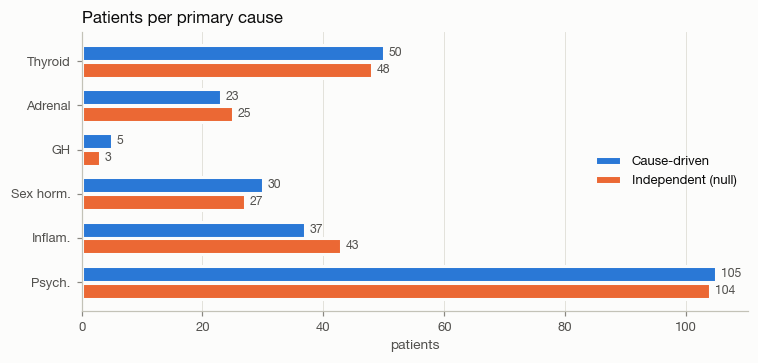

In [2]:
counts = pd.DataFrame({"Cause-driven": gt.primary_cause.value_counts(),
                       "Independent (null)": gt_null.primary_cause.value_counts()}).reindex(CAUSES).fillna(0)
fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(CAUSES))
for k, (name, color) in enumerate(zip(counts.columns, ["#2a78d6", "#eb6834"])):
    bars = ax.barh(y + (k - 0.5) * 0.38, counts[name], height=0.36, color=color, label=name,
                   edgecolor=SURFACE, linewidth=2)
    ax.bar_label(bars, padding=3, fontsize=8, color=INK_2, fmt="%d")
ax.set_yticks(y, [SHORT[c] for c in CAUSES])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("patients")
ax.set_title("Patients per primary cause")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

## 2. The presenting complaint looks the same for every cause

The proposal says all six causes present identically, so the complaint carries no information about the cause.

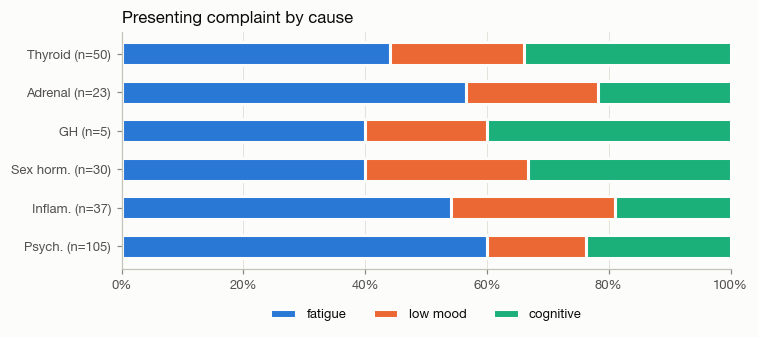

In [3]:
complaints = ["fatigue", "low_mood", "cognitive"]
share = pd.crosstab(gt.primary_cause, gt.presenting_complaint, normalize="index").reindex(CAUSES)[complaints]
fig, ax = plt.subplots(figsize=(7, 3.2))
left = np.zeros(len(CAUSES))
for name, color in zip(complaints, ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.barh(range(len(CAUSES)), share[name], left=left, color=color, height=0.6,
            edgecolor=SURFACE, linewidth=2, label=name.replace("_", " "))
    left += share[name].to_numpy()
n_by_cause = gt.primary_cause.value_counts()
ax.set_yticks(range(len(CAUSES)), [f"{SHORT[c]} (n={n_by_cause.get(c, 0)})" for c in CAUSES])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="y", visible=False)
ax.set_title("Presenting complaint by cause")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

## 3. Each cause's signature, with realistic overlap

Ground-truth values, one box per cause. The gray band is the normal reference interval. The matching cause
stands out, but every class overlaps the normal range, which is what keeps the problem hard.

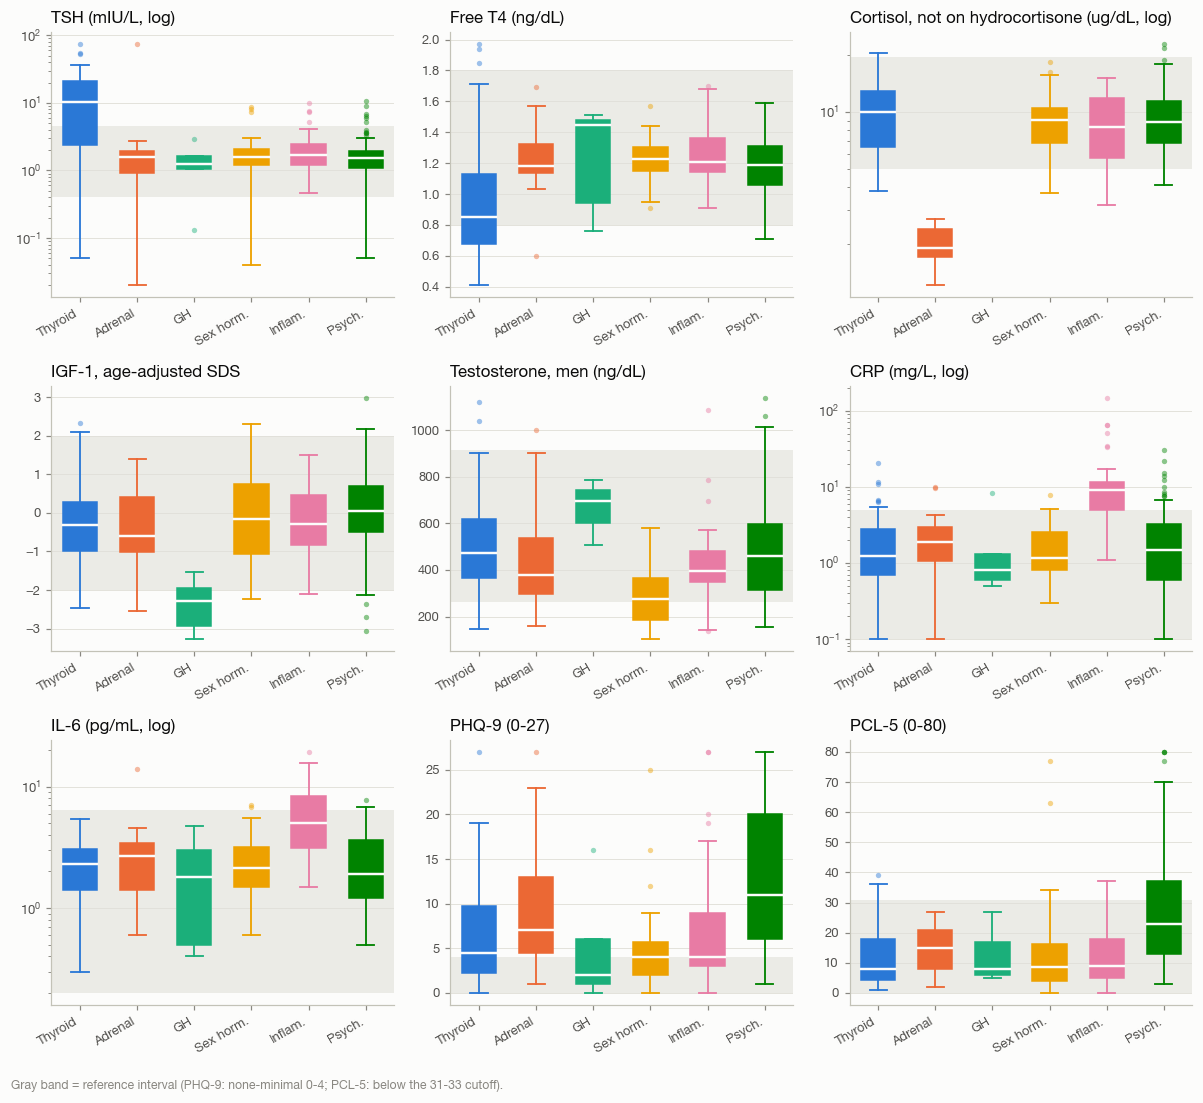

In [4]:
view = gt.assign(igf1_sds=igf1_sds(gt.igf1, gt.age))
panels = [
    (view, "tsh", "TSH (mIU/L, log)", True, (0.4, 4.5)),
    (view, "free_t4", "Free T4 (ng/dL)", False, (0.8, 1.8)),
    (view[view.hydrocortisone_mg_day == 0], "cortisol_am", "Cortisol, not on hydrocortisone (ug/dL, log)", True, (5, 19.5)),
    (view, "igf1_sds", "IGF-1, age-adjusted SDS", False, (-2, 2)),
    (view[view.sex == "M"], "testosterone", "Testosterone, men (ng/dL)", False, (264, 916)),
    (view, "crp", "CRP (mg/L, log)", True, (0.1, 5)),
    (view, "il6", "IL-6 (pg/mL, log)", True, (0.2, 6.4)),
    (view, "phq9", "PHQ-9 (0-27)", False, (0, 4)),
    (view, "pcl5", "PCL-5 (0-80)", False, (0, 31)),
]
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for ax, (df, col, title, log, ref) in zip(axes.flat, panels):
    cause_boxes(ax, df, col, title, log=log, ref=ref)
fig.text(0.01, 0.005, "Gray band = reference interval (PHQ-9: none-minimal 0-4; PCL-5: below the 31-33 cutoff).",
         color=MUTED, fontsize=8)
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

## 4. Missingness in `observed.csv` depends on the cause (missing not at random)

Share of patients with a value, by true cause. Cortisol is ordered mostly when adrenal failure is suspected, so
whether it is present is itself a signal. Tier 3 gaps come from refusals. Testosterone and estradiol are blank for one
sex by design.

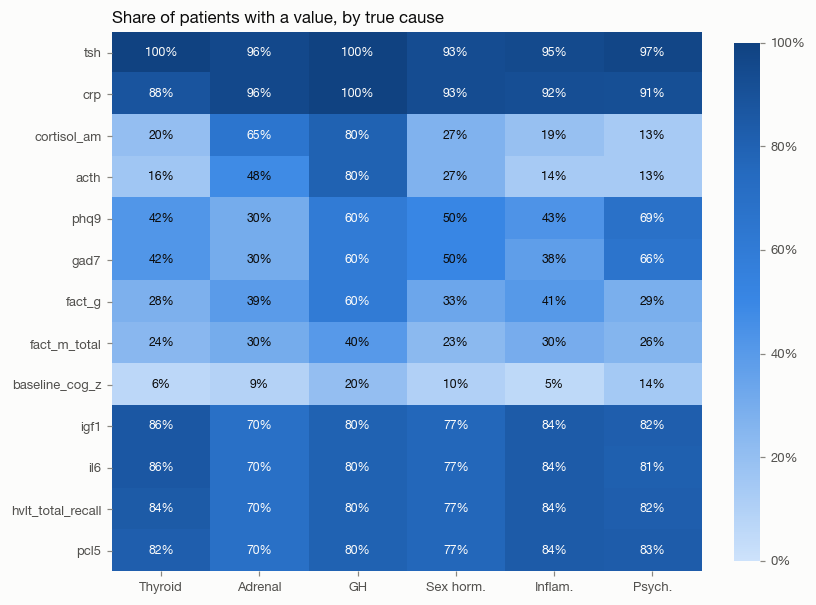

In [5]:
cols = ["tsh", "crp", "cortisol_am", "acth", "phq9", "gad7", "fact_g", "fact_m_total", "baseline_cog_z",
        "igf1", "il6", "hvlt_total_recall", "pcl5"]
present = obs[cols].notna().groupby(obs.primary_cause).mean().reindex(CAUSES).T
fig, ax = plt.subplots(figsize=(7.5, 5.6))
seq = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "blue_seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"])
im = ax.imshow(present.to_numpy(), cmap=seq, vmin=0, vmax=1, aspect="auto")
for (i, j), v in np.ndenumerate(present.to_numpy()):
    ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color=SURFACE if v > 0.55 else INK)
ax.set_xticks(range(len(CAUSES)), [SHORT[c] for c in CAUSES])
ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.set_title("Share of patients with a value, by true cause")
with plt.rc_context({"axes.grid": False}):
    plt.colorbar(im, ax=ax, fraction=0.04, format=plt.matplotlib.ticker.PercentFormatter(1)).outline.set_visible(False)
plt.tight_layout()
plt.show()

## 5. Correlation structure (what PCA will find later)

Spearman correlations between the measured ground-truth columns. Labs and scores driven by a shared hidden factor
cluster together: inflammation (CRP, IL-6, TNF-alpha, neutrophils, platelets), distress (PHQ-9, GAD-7, PCL-5,
FACT) and cognition (HVLT-R, Trail Making B, COWA).

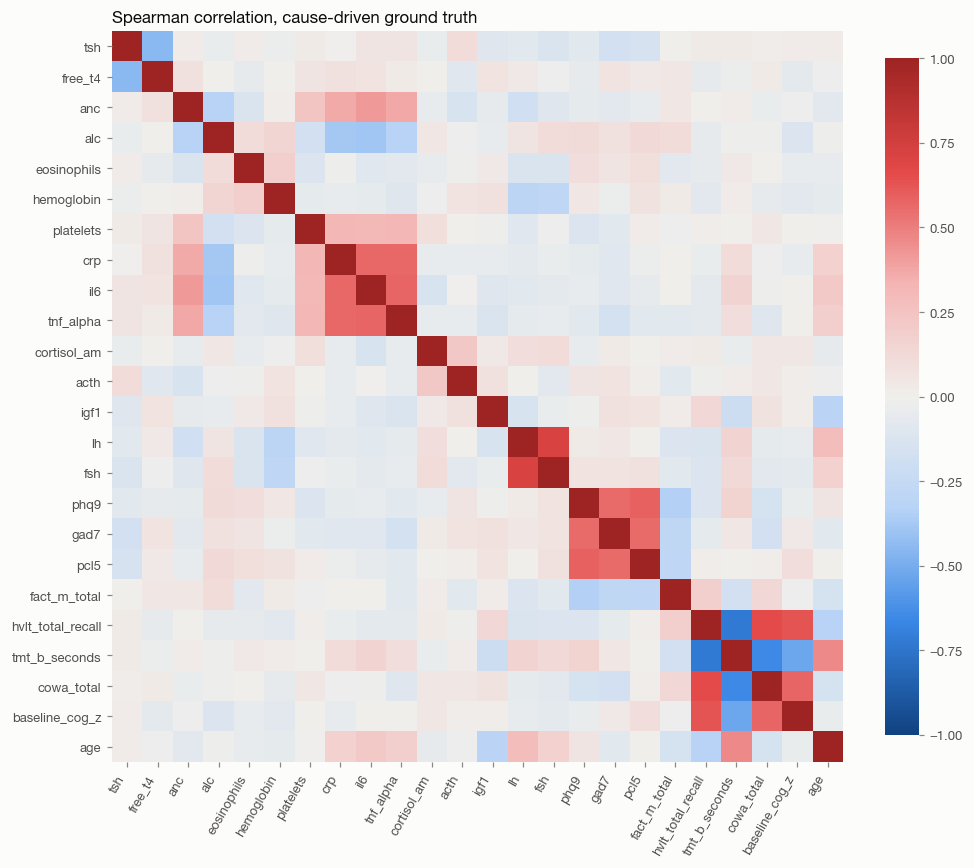

In [6]:
num = ["tsh", "free_t4", "anc", "alc", "eosinophils", "hemoglobin", "platelets", "crp", "il6", "tnf_alpha",
       "cortisol_am", "acth", "igf1", "lh", "fsh", "phq9", "gad7", "pcl5", "fact_m_total",
       "hvlt_total_recall", "tmt_b_seconds", "cowa_total", "baseline_cog_z", "age"]
corr = gt[num].corr(method="spearman")
div = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "blue_red", ["#104281", "#3987e5", "#b7d3f6", "#f0efec", "#f4b5b4", "#e34948", "#9e2423"])
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr.to_numpy(), cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(len(num)), num, rotation=60, ha="right")
ax.set_yticks(range(len(num)), num)
ax.grid(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.set_title("Spearman correlation, cause-driven ground truth")
with plt.rc_context({"axes.grid": False}):
    plt.colorbar(im, ax=ax, fraction=0.04).outline.set_visible(False)
plt.tight_layout()
plt.show()

## 6. Per-cause scores (the regression targets)

Each patient has six shares of symptom burden that sum to 1. The label is the largest. Most patients have one
dominant cause, and about a quarter have a meaningful second one.

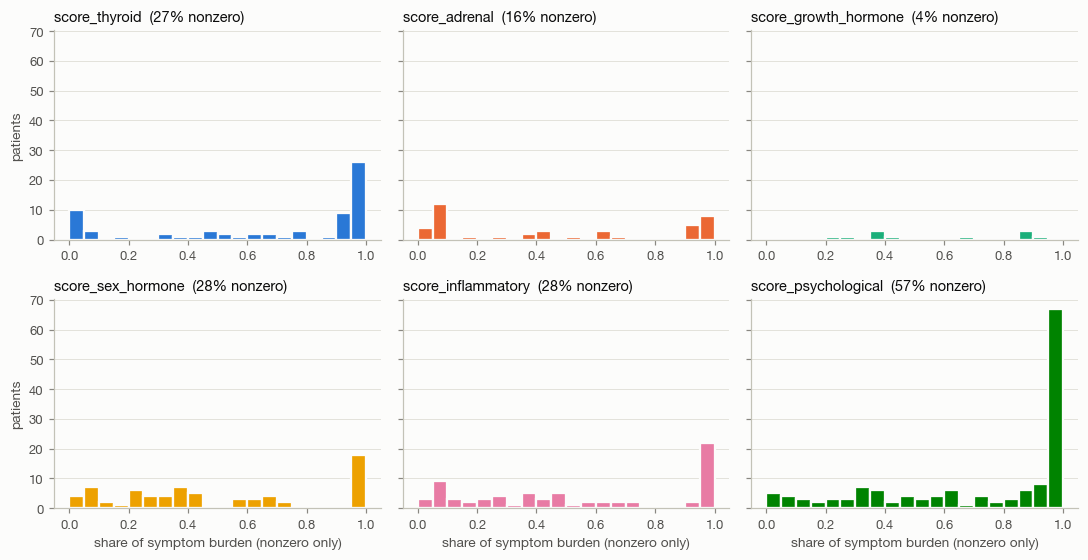

                       mean    50%    max
score_thyroid         0.184  0.000  1.000
score_adrenal         0.076  0.000  1.000
score_growth_hormone  0.025  0.000  0.916
score_sex_hormone     0.141  0.000  1.000
score_inflammatory    0.155  0.000  1.000
score_psychological   0.418  0.274  1.000


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5.2), sharey=True)
for ax, c in zip(axes.flat, CAUSES):
    vals = gt[f"score_{c}"]
    ax.hist(vals[vals > 0], bins=np.linspace(0, 1, 21), color=CAUSE_COLOR[c], edgecolor=SURFACE, linewidth=1.5)
    ax.set_title(f"score_{c}  ({(vals > 0).mean():.0%} nonzero)", fontsize=9.5)
    ax.grid(axis="x", visible=False)
for ax in axes[1]:
    ax.set_xlabel("share of symptom burden (nonzero only)")
for ax in axes[:, 0]:
    ax.set_ylabel("patients")
plt.tight_layout()
plt.show()
print(gt[[f"score_{c}" for c in CAUSES]].describe().round(3).T[["mean", "50%", "max"]])

## 7. Null check: the independent mode has no signal

The same TSH panel, cause-driven vs independent. In the null data every cause looks the same, so a model scoring
above chance there is finding something that isn't real.

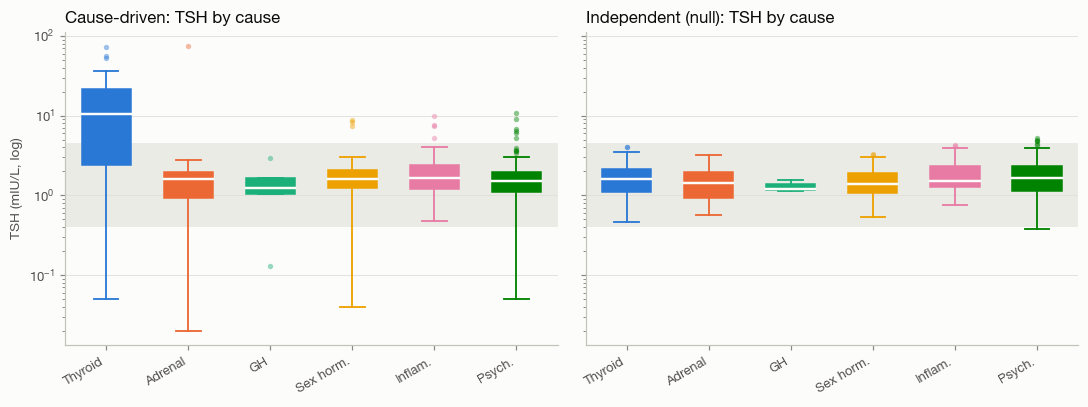

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
cause_boxes(axes[0], gt, "tsh", "Cause-driven: TSH by cause", log=True, ref=(0.4, 4.5))
cause_boxes(axes[1], gt_null, "tsh", "Independent (null): TSH by cause", log=True, ref=(0.4, 4.5))
axes[0].set_ylabel("TSH (mIU/L, log)")
plt.tight_layout()
plt.show()

## 8. Variables and typical ranges

The full table is in `data/data_dictionary.csv` (99 rows, including the hidden ground-truth columns).

In [9]:
pd.set_option("display.max_colwidth", 70)
dictionary.loc[dictionary.tier.isin(["demographic", "1", "2", "3"]),
               ["name", "tier", "unit", "normal", "lod", "source"]].fillna("").reset_index(drop=True)

,name,tier,unit,normal,lod,source
0,age,demographic,years,"25-90, mean ~61",,Typical age of melanoma ICI cohorts (median ~60-62)
1,sex,demographic,,~62% male,,Male share in melanoma ICI trials (~60-65%)
2,menopausal_status,demographic,,post if age >~51,,Median age at natural menopause ~51
3,regimen,1,,anti-PD-1 60% / anti-CTLA-4 10% / combination 30%,,Assumed MSK survivor mix (adjuvant PD-1 common; combination for st...
4,stage_at_diagnosis,1,,II 10% / III 45% / IV 45%,,Assumption
5,months_since_therapy_end,1,months,"12-96, median ~30",,Eligibility: 12+ months past therapy
6,irae_thyroiditis,1,,,,Barroso-Sousa 2018 JAMA Oncol (endocrine irAE meta-analysis); Faje...
7,irae_hypophysitis,1,,,,Barroso-Sousa 2018 JAMA Oncol (endocrine irAE meta-analysis); Faje...
8,irae_adrenalitis,1,,,,Barroso-Sousa 2018 JAMA Oncol (endocrine irAE meta-analysis); Faje...
9,irae_colitis,1,,,,CheckMate 067 / KEYNOTE-054 any-grade rates (approx.)
